# Train on renders, test on real photos
Can the shape fingerprint learn from **LDraw renders only** (no photos) and still recognize **real** bricks?
1. Render N views of every part × color (`ldraw_render.py`, ~1 ms each) → `renders/`.
2. Make renders look like photos: random background, shadow, blur, noise, JPEG.
3. Train the color-blind fingerprint on renders only; the 3 held-out shapes are never trained on (same as lookup.ipynb).
4. Test on the real **test** photos: gallery from renders only vs. gallery from real photos.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, sys, time, glob
from collections import defaultdict, Counter
import cv2, numpy as np, torch, torchvision, matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T
sys.path.insert(0, '.'); import importlib, lego_lookup as L, ldraw_render as R; importlib.reload(L); importlib.reload(R)

lab = {r['path']: r for r in csv.DictReader(open('data/labels.csv'))}
LD = {r['lego_id']: r['ldraw_code'] for r in csv.DictReader(open('data/lego_colors.csv'))}
ELEMS = sorted({(r['part_num'], r['lego_color_id']) for r in lab.values()})
ranges = [(int(r['start']), int(r['end'])) for r in csv.DictReader(open('data/ranges.csv'))]
runs = defaultdict(list)   # same per-run 70/15/15 split as compare.ipynb
for p in {r['path'] for r in csv.DictReader(open('data/boxes.csv'))}:
    runs[next(i for i, (a, b) in enumerate(ranges) if a <= int(os.path.basename(p)[4:8]) <= b)].append(p)
split = {p: 'train' if i < 0.7 * len(ps) else 'val' if i < 0.85 * len(ps) else 'test' for ps in runs.values() for i, p in enumerate(sorted(ps))}
P = {k: sorted(p for p in split if split[p] == k) for k in ('train', 'val', 'test')}
crop = lambda p: cv2.cvtColor(cv2.imread('crops224/' + p), cv2.COLOR_BGR2RGB)

HOLD = ['15254', '92950', '3062b']   # never trained on: stand-ins for future new pieces
SHAPES = sorted({p for p, _ in ELEMS} - set(HOLD)); SI = {s: i for i, s in enumerate(SHAPES)}
print(len(ELEMS), 'elements,', len(SHAPES), 'trained shapes +', len(HOLD), 'held out')

41 elements, 22 trained shapes + 3 held out


## 1. Render (~1 min, cached in `renders/`)

In [2]:
N_RENDER = 400   # views per element
t = time.time(); rng = np.random.default_rng(0)
for part, cid in ELEMS:
    d = f'renders/{part}_{cid}'; os.makedirs(d, exist_ok=True)
    for i in range(len(os.listdir(d)), N_RENDER):
        cv2.imwrite(f'{d}/{i:04d}.png', cv2.cvtColor(R.render(part, LD[cid], 224, rng), cv2.COLOR_RGBA2BGRA))
RENDERS = sorted(glob.glob('renders/*/*.png'))
print(len(RENDERS), f'renders ({time.time() - t:.0f}s)')

16400 renders (0s)


## 2. Make renders look like photos
Real crops: brick on a table, soft shadow, slight blur, sensor noise, JPEG. Renders get the same, randomly.

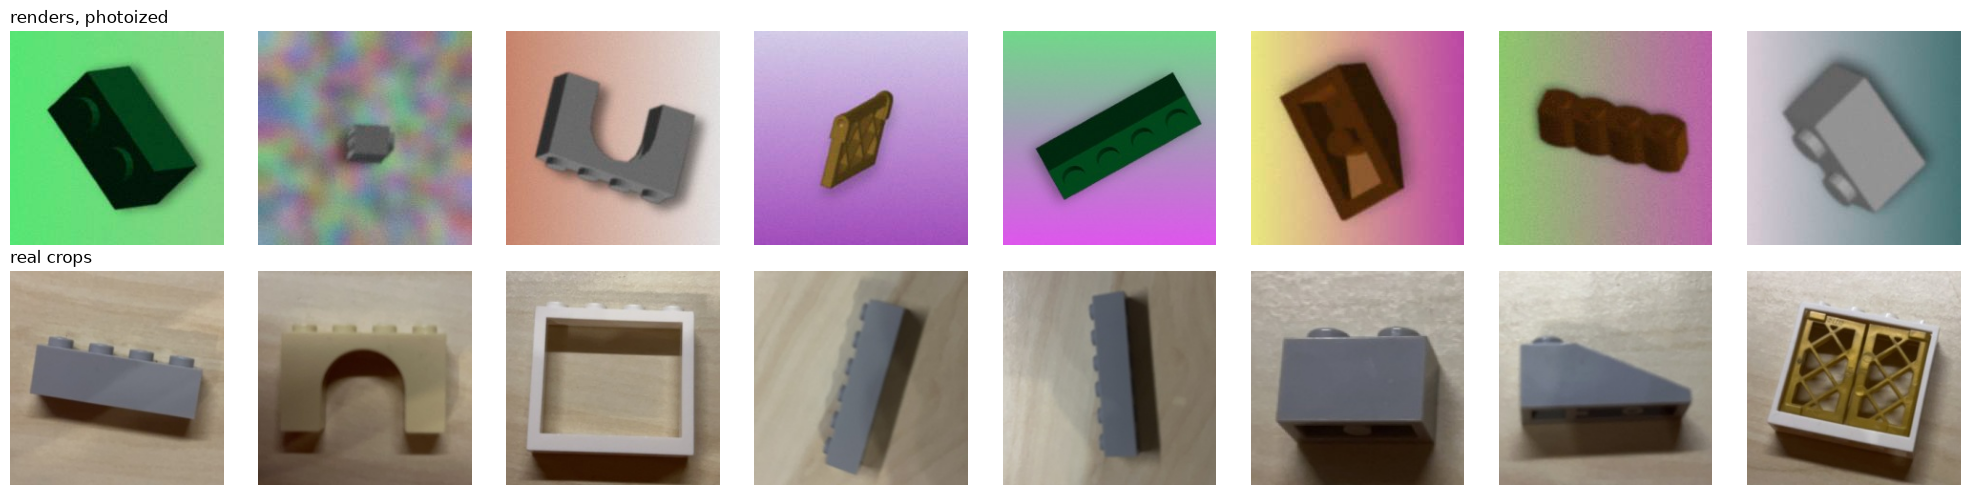

In [3]:
def photoize(rgba, rng):
    S = rgba.shape[0]
    k = rng.integers(3)   # background: plain table / gradient / blurred texture
    if k == 0: bg = np.ones((S, S, 3)) * rng.uniform(60, 240, 3)
    elif k == 1:
        g = np.linspace(0, 1, S)[:, None, None] if rng.random() < .5 else np.linspace(0, 1, S)[None, :, None]
        bg = rng.uniform(60, 240, 3) * (1 - g) + rng.uniform(60, 240, 3) * g; bg = np.broadcast_to(bg, (S, S, 3))
    else: bg = cv2.GaussianBlur(rng.uniform(40, 240, (S // 8, S // 8, 3)), (0, 0), 1); bg = cv2.resize(bg, (S, S))
    f = rng.uniform(0.75, 1.05); M = np.float32([[f, 0, (1 - f) * S / 2 + rng.normal(0, 6)], [0, f, (1 - f) * S / 2 + rng.normal(0, 6)]])
    rgba = cv2.warpAffine(rgba, M, (S, S))   # size/position jitter like a detector box
    a = rgba[..., 3:] / 255
    sh = cv2.GaussianBlur(np.roll(a[..., 0], rng.integers(-10, 11, 2), (0, 1)), (0, 0), rng.uniform(3, 10))[..., None]
    img = bg * (1 - rng.uniform(0.2, 0.6) * sh)              # soft shadow under the brick
    img = rgba[..., :3] * a + img * (1 - a)
    img = cv2.GaussianBlur(img, (0, 0), rng.uniform(0.3, 1.5)) + rng.normal(0, rng.uniform(1, 6), img.shape)
    img = np.clip(img, 0, 255).astype(np.uint8)
    return cv2.imdecode(cv2.imencode('.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(40, 95))])[1], cv2.IMREAD_COLOR)

rng = np.random.default_rng(1); show = np.random.default_rng(2).choice(RENDERS, 8, replace=False)
real = [crop(p) for p in np.random.default_rng(3).choice(P['train'], 8, replace=False)]
fig, ax = plt.subplots(2, 8, figsize=(20, 5))
for a, p in zip(ax[0], show): a.imshow(photoize(cv2.cvtColor(cv2.imread(p, cv2.IMREAD_UNCHANGED), cv2.COLOR_BGRA2RGBA), rng)); a.axis('off')
for a, c in zip(ax[1], real): a.imshow(c); a.axis('off')
ax[0, 0].set_title('renders, photoized', loc='left'); ax[1, 0].set_title('real crops', loc='left'); plt.tight_layout(); plt.show()

## 3. Train the fingerprint on renders only (~5 min, skipped if `models/shape_embed_render.pt` exists)

In [4]:
EMBED_RENDER = 'models/shape_embed_render.pt'
norm = T.Compose([T.ToDtype(torch.float32, scale=True), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
aug = T.Compose([T.RandomRotation(180), T.RandomHorizontalFlip(), T.ColorJitter(0.4, 0.4), norm])

class Renders(Dataset):
    def __init__(s): s.ps = [p for p in RENDERS if p.split('/')[1].rsplit('_', 1)[0] in SI]
    def __len__(s): return len(s.ps)
    def __getitem__(s, i):
        p = s.ps[i]; rng = np.random.default_rng()
        img = photoize(cv2.cvtColor(cv2.imread(p, cv2.IMREAD_UNCHANGED), cv2.COLOR_BGRA2RGBA), rng)
        return aug(torch.from_numpy(L.gray3(img)).permute(2, 0, 1)), SI[p.split('/')[1].rsplit('_', 1)[0]]

class Real(Dataset):   # real val photos: only to watch progress, never trained on
    def __init__(s, ps): s.ps = [p for p in ps if lab[p]['part_num'] in SI]
    def __len__(s): return len(s.ps)
    def __getitem__(s, i): return norm(torch.from_numpy(L.gray3(crop(s.ps[i]))).permute(2, 0, 1)), SI[lab[s.ps[i]]['part_num']]

if not os.path.exists(EMBED_RENDER):
    m = torchvision.models.resnet18(weights='DEFAULT'); m.fc = torch.nn.Linear(512, len(SHAPES)); m = m.to(L.DEV)
    tl = DataLoader(Renders(), batch_size=64, shuffle=True, num_workers=12, persistent_workers=True)
    vl = DataLoader(Real(P['val']), batch_size=128, num_workers=8)
    EP = 12; opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=EP * len(tl)); scaler = torch.amp.GradScaler()
    for ep in range(EP):
        m.train(); t = time.time()
        for x, y in tl:
            with torch.autocast('cuda'): loss = torch.nn.functional.cross_entropy(m(x.to(L.DEV)), y.to(L.DEV), label_smoothing=0.1)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()
        m.eval(); ok = n = 0
        with torch.no_grad():
            for x, y in vl: ok += (m(x.to(L.DEV)).argmax(1).cpu() == y).sum().item(); n += len(y)
        print(f'epoch {ep}: REAL val shape acc {ok / n:.3f} ({time.time() - t:.0f}s)')
    torch.save({k: v for k, v in m.state_dict().items() if not k.startswith('fc.')}, EMBED_RENDER)

## 4. Test on real photos
Gallery from **renders only** (100 photoized views per element) vs. gallery from **real photos** (20 per element, as in lookup.ipynb).

In [5]:
test = P['test']; tc = [crop(p) for p in test]
held = np.array([lab[p]['part_num'] in HOLD for p in test])
rng = np.random.default_rng(5)
by_elem = defaultdict(list)
for p in RENDERS: by_elem[p.split('/')[1]].append(p)
r_crops, r_shape = [], []
for e, ps in sorted(by_elem.items()):
    for p in ps[:100]: r_crops.append(photoize(cv2.cvtColor(cv2.imread(p, cv2.IMREAD_UNCHANGED), cv2.COLOR_BGRA2RGBA), rng)); r_shape.append(e.rsplit('_', 1)[0])
real_g = L.load_gallery()   # data/gallery.npz: 20 real photos per element

rows = []
for name, path in [('trained on real photos', L.EMBED_PT), ('trained on renders only', EMBED_RENDER)]:
    m = L.load_embedder(path); tv = L.embed(m, tc)
    for gname, g in [('render gallery', dict(vec=L.embed(m, r_crops), shape=np.array(r_shape))),
                     ('real-photo gallery', dict(vec=L.embed(m, [crop(p) for p in real_g['src']]), shape=real_g['shape']))]:
        g = {**g, 'lab': np.zeros((len(g['shape']), 3), np.float32), 'color': np.array(['?'] * len(g['shape']))}
        ok = np.array([r[0] == lab[p]['part_num'] for r, p in zip(L.recognize(g, tv, np.zeros((len(tv), 3), np.float32), shape_min_sim=-1), test)])
        rows.append((name, gname, ok.mean(), ok[held].mean()))
print(f"{'fingerprint':26} {'gallery':20} {'shape acc':>9} {'held-out':>9}")
for r in rows: print(f'{r[0]:26} {r[1]:20} {r[2]:9.3f} {r[3]:9.3f}')

fingerprint                gallery              shape acc  held-out
trained on real photos     render gallery           0.608     0.190
trained on real photos     real-photo gallery       0.989     0.976
trained on renders only    render gallery           0.823     0.333
trained on renders only    real-photo gallery       0.958     0.857


In [ ]:
get_ipython().kernel.do_shutdown(False)   # last cell: kills this kernel so GPU/RAM is freed after Run All

{'status': 'ok', 'restart': False}

: 